<a href="https://colab.research.google.com/github/612202500225-ILHAM/F12_2025_00225_ILHAM_BAGUS_SAPUTRA_/blob/main/UTS%20PENAMBANGAN%20DATA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi dengan Naive Bayes
**Mata Kuliah:** Data Mining
**Dataset:** Volume Timbunan Sampah per Hari per Kecamatan

**Tujuan:** mengklasifikasikan kecamatan ke dalam kelas volume sampah **Rendah (0)** atau **Tinggi (1)** berdasarkan jumlah penduduk dan volume sampah (m³).

## 1. Import library yang digunakan


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 2. Import dataset


In [ ]:
dataset = pd.read_csv('volume-sampah.csv')
print("Jumlah baris & kolom:", dataset.shape)
dataset

Jumlah baris & kolom: (18, 4)


,kecamatan,jumlah_penduduk_kecamatan_jiwa,volume_timbunan_sampah_per_hari_m3,volume_timbunan_sampah_per_hari_ton
0,Labuhanhaji Barat,17069,6827.6,6.83
1,Labuhanhaji,12899,5159.6,5.16
2,Labuhanhaji Timur,10212,4084.8,4.08
3,Meukek,19515,7806.0,7.81
4,Sawang,15853,6341.2,6.34
5,Samadua,15613,6245.2,6.25
6,Tapaktuan,23341,9336.4,9.34
7,Pasie Raja,18514,7405.6,7.41
8,Kluet Utara,26332,10532.8,10.53
9,Kluet Tengah,7036,2814.4,2.81


### Membuat kolom kelas (target)
Naive Bayes adalah algoritma **klasifikasi**, sehingga targetnya harus berupa kategori. Dataset ini hanya berisi angka, jadi kita buat sendiri kolom kelas dari `volume_timbunan_sampah_per_hari_ton`:

- **0 = Rendah** → volume sampah (ton) **≤ median**
- **1 = Tinggi** → volume sampah (ton) **> median**

Median dipilih agar jumlah kelas 0 dan 1 seimbang.

In [ ]:
batas = dataset['volume_timbunan_sampah_per_hari_ton'].median()
print("Batas (median) ton/hari:", batas)

dataset['kelas'] = (dataset['volume_timbunan_sampah_per_hari_ton'] > batas).astype(int)
print(dataset['kelas'].value_counts())
dataset[['kecamatan', 'volume_timbunan_sampah_per_hari_ton', 'kelas']]

Batas (median) ton/hari: 5.27
kelas
1    9
0    9
Name: count, dtype: int64


,kecamatan,volume_timbunan_sampah_per_hari_ton,kelas
0,Labuhanhaji Barat,6.83,1
1,Labuhanhaji,5.16,0
2,Labuhanhaji Timur,4.08,0
3,Meukek,7.81,1
4,Sawang,6.34,1
5,Samadua,6.25,1
6,Tapaktuan,9.34,1
7,Pasie Raja,7.41,1
8,Kluet Utara,10.53,1
9,Kluet Tengah,2.81,0


### Menentukan fitur (X) dan target (y)
- **X** = kolom indeks 1 dan 2: `jumlah_penduduk_kecamatan_jiwa` dan `volume_timbunan_sampah_per_hari_m3`
- **y** = kolom terakhir (`kelas`)


In [ ]:
X = dataset.iloc[:, [1, 2]].values
y = dataset.iloc[:, -1].values
print("X (5 baris pertama):\n", X[:5])
print("y:", y)

X (5 baris pertama):
 [[17069.   6827.6]
 [12899.   5159.6]
 [10212.   4084.8]
 [19515.   7806. ]
 [15853.   6341.2]]
y: [1 0 0 1 1 1 1 1 1 0 1 1 0 0 0 0 0 0]


## 3. Splitting dataset menjadi Training set dan Test set
75% data untuk melatih model, 25% untuk menguji (`test_size = 0.25`).

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

## 4. Feature Scaling


In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
print(X_train[:5])

[[ 0.83852186  0.83852186]
 [-0.2932689  -0.2932689 ]
 [-1.1343373  -1.1343373 ]
 [-0.40181327 -0.40181327]
 [-0.93049057 -0.93049057]]


## 5. Training model Naive Bayes pada Training set

In [ ]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)

GaussianNB()

## 6. Memprediksi hasil Test set

In [ ]:
y_pred = classifier.predict(X_test)
hasil = pd.DataFrame({'Kelas Asli': y_test, 'Kelas Prediksi': y_pred})
hasil

,Kelas Asli,Kelas Prediksi
0,0,1
1,1,1
2,1,1
3,1,1
4,0,0


## 7. Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("Akurasi:", accuracy_score(y_test, y_pred))

[[1 1]
 [0 3]]
Akurasi: 0.8


## 8. Visualisasi hasil Training set
Area merah = prediksi kelas 0 (Rendah), area hijau = prediksi kelas 1 (Tinggi). Titik adalah data asli.

/tmp/ipykernel_2499/586926649.py:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


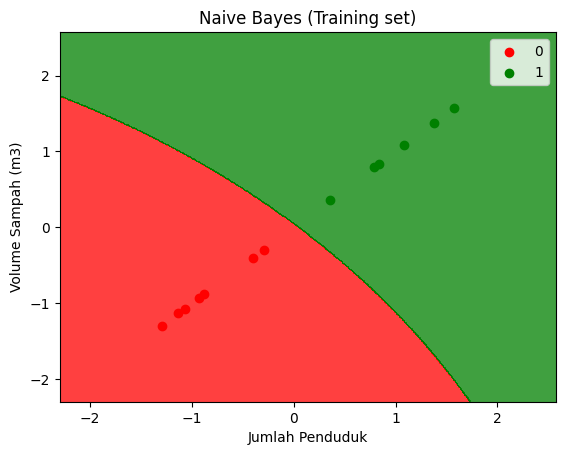

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green'))(i), label = j)
plt.title('Naive Bayes (Training set)')
plt.xlabel('Jumlah Penduduk')
plt.ylabel('Volume Sampah (m3)')
plt.legend()
plt.show()

## 9. Visualisasi hasil Test set

/tmp/ipykernel_2499/1208939782.py:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


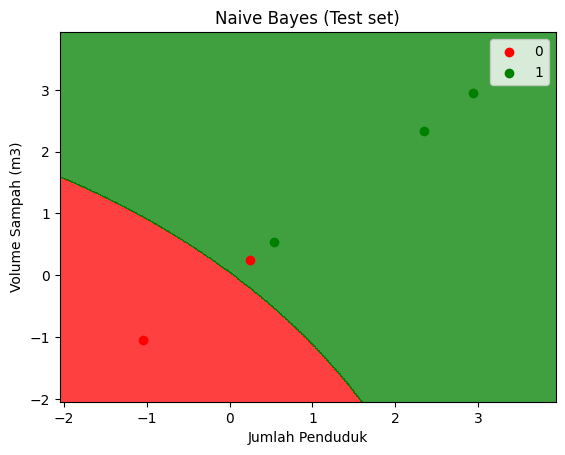

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = X_test, y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green'))(i), label = j)
plt.title('Naive Bayes (Test set)')
plt.xlabel('Jumlah Penduduk')
plt.ylabel('Volume Sampah (m3)')
plt.legend()
plt.show()